In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

print("Libraries imported successfully!")

Libraries imported successfully!


In [5]:
file_path = "/kaggle/input/datasets/arashnic/fitbit/mturkfitbit_export_3.12.16-4.11.16/Fitabase Data 3.12.16-4.11.16/heartrate_seconds_merged.csv"
df = pd.read_csv(file_path)

display(df.head())

df_sample = df.head(1000).copy()

X = np.arange(len(df_sample))
Y = df_sample['Value'].values

X = (X - X.mean()) / X.std()
Y = (Y - Y.mean()) / Y.std()

,Id,Time,Value
0,2022484408,4/1/2016 7:54:00 AM,93
1,2022484408,4/1/2016 7:54:05 AM,91
2,2022484408,4/1/2016 7:54:10 AM,96
3,2022484408,4/1/2016 7:54:15 AM,98
4,2022484408,4/1/2016 7:54:20 AM,100


In [6]:
degree = 3
X_poly = np.vstack([X**i for i in range(degree + 1)]).T

print("Shape of X_poly:", X_poly.shape)

Shape of X_poly: (1000, 4)


In [7]:
def minibatch_gradient_descent(X, Y, learning_rate=0.01, batch_size=32, epochs=100):
    m, n = X.shape
    weights = np.zeros(n)
    loss_history = []
    
    for epoch in range(epochs):
        indices = np.arange(m)
        np.random.shuffle(indices)
        X_shuffled = X[indices]
        Y_shuffled = Y[indices]
        
        for i in range(0, m, batch_size):
            X_batch = X_shuffled[i:i + batch_size]
            Y_batch = Y_shuffled[i:i + batch_size]
            
            batch_m = len(X_batch)
            prediction = np.dot(X_batch, weights)
            error = prediction - Y_batch
            
            dw = (1 / batch_m) * np.dot(X_batch.T, error)
            weights -= learning_rate * dw
            
        Y_pred_all = np.dot(X, weights)
        epoch_loss = (1 / (2 * m)) * np.sum((Y_pred_all - Y) ** 2)
        loss_history.append(epoch_loss)
        
    return weights, loss_history

learning_rate = 0.05
batch_size = 64
epochs = 150
optimal_weights, losses = minibatch_gradient_descent(X_poly, Y, learning_rate, batch_size, epochs)

print("Final Loss for Mini-Batch:", losses[-1])

Final Loss for Mini-Batch: 0.08208322967427668


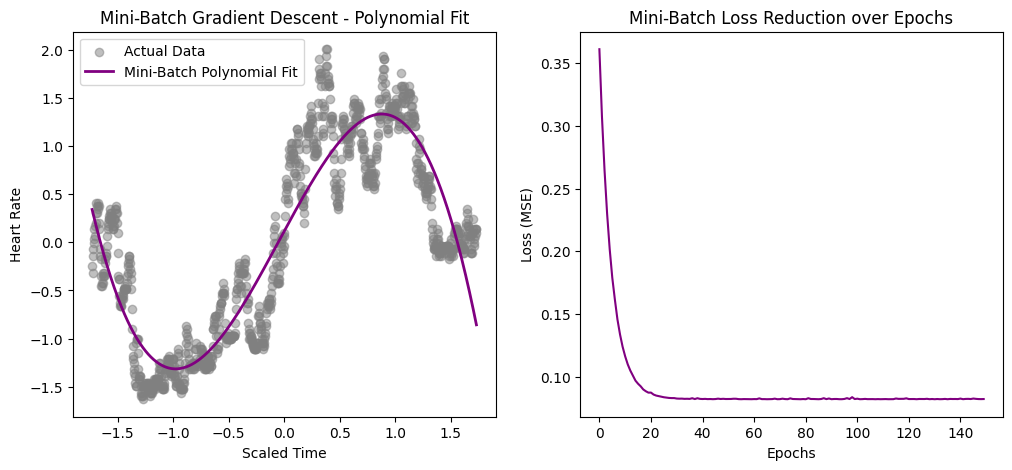

In [8]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
plt.scatter(X, Y, color='gray', alpha=0.5, label='Actual Data')
plt.plot(X, np.dot(X_poly, optimal_weights), color='purple', linewidth=2, label='Mini-Batch Polynomial Fit')
plt.xlabel('Scaled Time')
plt.ylabel('Heart Rate')
plt.legend()
plt.title('Mini-Batch Gradient Descent - Polynomial Fit')

plt.subplot(1, 2, 2)
plt.plot(losses, color='purple')
plt.xlabel('Epochs')
plt.ylabel('Loss (MSE)')
plt.title('Mini-Batch Loss Reduction over Epochs')

plt.show()